<a href="https://colab.research.google.com/github/rpasquini/herramientas-econometricas/blob/main/OLS_2_Ajuste_Propiedades_Test_de_Hip%C3%B3tesis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión lineal simple: estimación, propiedades e inferencia

Este notebook acompaña las slides del Día 2. Seguimos el mismo ejemplo: **ingresos y años de escolaridad en CABA (EAH 2016)**. El modelo es

$$\log(ingreso_i)=\beta_0+\beta_1\, aesc_i+\varepsilon_i$$

Plan:
1. Datos
2. Estimación por MCO
3. Predicción
4. Bondad de ajuste
5. Propiedades estadísticas: simulación de la distribución muestral de $\hat\beta_1$
6. Tests de hipótesis e intervalos de confianza
7. Práctica

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

## 1. Datos

In [2]:
url = 'https://raw.githubusercontent.com/rpasquini/herramientas-econometricas/main/datos/eah2016_individual.csv'
df = pd.read_csv(url)
df.shape

(14512, 96)

Variables que usamos: `ingtot_2` (ingreso total individual) y `aesc` (años de escolaridad; los códigos 0 y 99 no son años válidos). Nos quedamos con los ingresos positivos para poder tomar logaritmo.

In [3]:
df = df[(df['ingtot_2'] > 0) & (df['aesc'] != 0) & (df['aesc'] != 99)].copy()
df['logingreso'] = np.log(df['ingtot_2'])
df[['ingtot_2', 'logingreso', 'aesc']].describe()

,ingtot_2,logingreso,aesc
count,10048.000000,10048.000000,10048.000000
mean,14950.692377,9.286783,12.623507
std,13809.190119,0.858955,3.735864
min,24.000000,3.178054,1.000000
25%,6000.000000,8.699515,10.000000
50%,12000.000000,9.392662,12.000000
75%,19461.750000,9.876206,15.000000
max,276000.000000,12.528156,19.000000


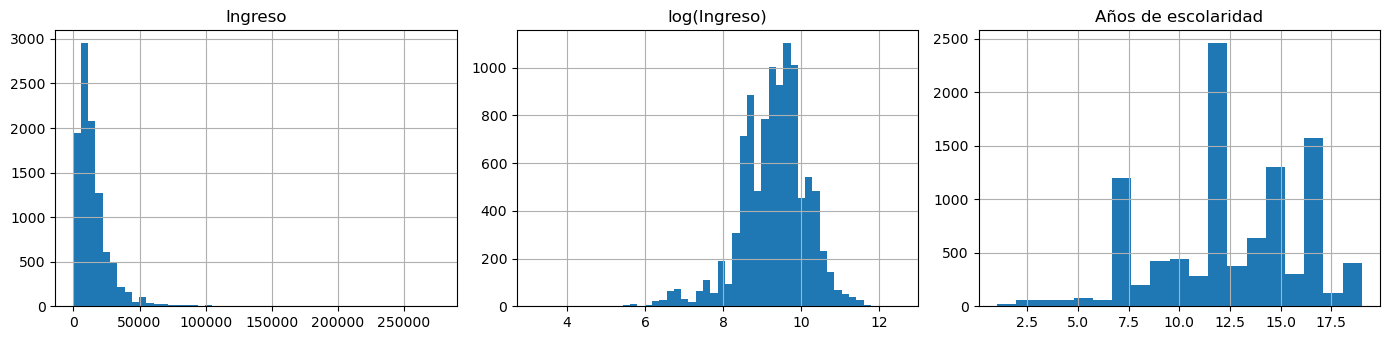

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.5))
df['ingtot_2'].hist(bins=50, ax=axs[0]); axs[0].set_title('Ingreso')
df['logingreso'].hist(bins=50, ax=axs[1]); axs[1].set_title('log(Ingreso)')
df['aesc'].hist(bins=19, ax=axs[2]); axs[2].set_title('Años de escolaridad')
plt.tight_layout()

## 2. Estimación por MCO

Usamos directamente la sintaxis de fórmulas de `statsmodels`: `'y ~ x'`. Por defecto agrega la constante y descarta las filas con valores faltantes.

In [5]:
res = smf.ols('logingreso ~ aesc', data=df).fit()
print(res.summary())

                            OLS Regression Results                            
Dep. Variable:             logingreso   R-squared:                       0.197
Model:                            OLS   Adj. R-squared:                  0.197
Method:                 Least Squares   F-statistic:                     2460.
Date:                Wed, 21 Oct 2026   Prob (F-statistic):               0.00
Time:                        21:38:47   Log-Likelihood:                -11629.
No. Observations:               10048   AIC:                         2.326e+04
Df Residuals:                   10046   BIC:                         2.328e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      7.9995      0.027    295.553      0.0

**Cómo leer la tabla**: `coef` es $\hat\beta$; `std err` es $SE(\hat\beta)$; `t` es $\hat\beta/SE(\hat\beta)$ (test de $H_0:\beta=0$); `P>|t|` es el p-valor de dos colas; `[0.025 0.975]` es el intervalo de confianza al 95%.

### Los estimadores a mano

$$\hat\beta_1=\frac{\widehat{Cov}(X,Y)}{\widehat{Var}(X)},\qquad \hat\beta_0=\bar Y-\hat\beta_1\bar X$$

In [6]:
x = df['aesc']
y = df['logingreso']

b1 = np.cov(x, y, ddof=1)[0, 1] / np.var(x, ddof=1)
b0 = y.mean() - b1 * x.mean()
print('A mano :', b0, b1)
print('statsmodels:', res.params['Intercept'], res.params['aesc'])

A mano : 7.999487197754181 0.10197609134201671
statsmodels: 7.999487197754161 0.10197609134201842


### Interpretación
Como la variable dependiente está en logaritmos, $100\times\hat\beta_1$ es (aproximadamente) el cambio porcentual del ingreso por cada año adicional de escolaridad. La expresión exacta es $e^{\hat\beta_1}-1$.

In [7]:
print(f"Un año más de escolaridad se asocia con un ingreso {100*(np.exp(res.params['aesc'])-1):.1f}% mayor")

Un año más de escolaridad se asocia con un ingreso 10.7% mayor


### Comparación: ingreso en niveles

¿Por qué trabajamos con logaritmos? Estimemos el modelo con el ingreso en pesos.

In [8]:
res_niv = smf.ols('ingtot_2 ~ aesc', data=df).fit()
print(res_niv.params)
print('R2 niveles:', round(res_niv.rsquared, 3), '  R2 logs:', round(res.rsquared, 3))

Intercept   -4287.521326
aesc         1523.999111
dtype: float64
R2 niveles: 0.17   R2 logs: 0.197


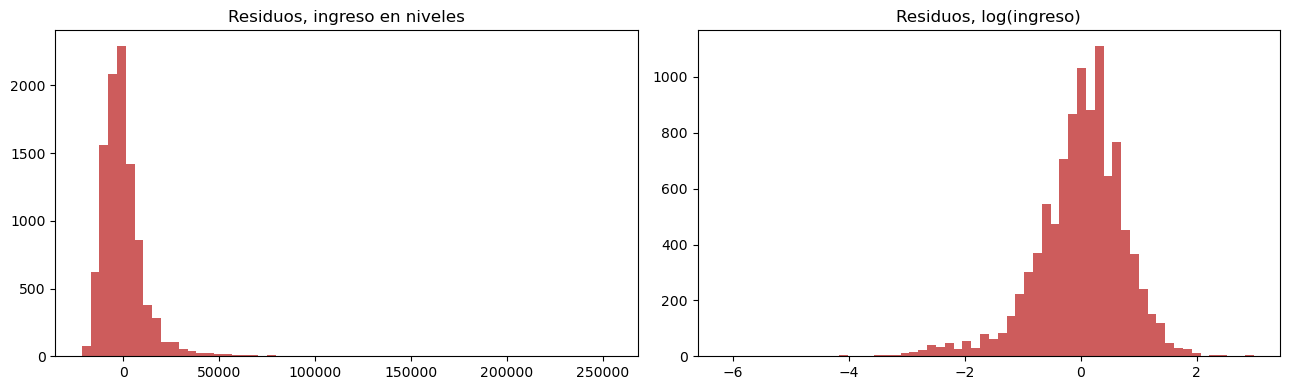

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(13, 4))
axs[0].hist(res_niv.resid, bins=60, color='indianred'); axs[0].set_title('Residuos, ingreso en niveles')
axs[1].hist(res.resid, bins=60, color='indianred'); axs[1].set_title('Residuos, log(ingreso)')
plt.tight_layout()

En niveles el coeficiente se interpreta en pesos y los residuos están muy concentrados con una cola derecha larguísima. En logs la interpretación es porcentual y la distribución de los residuos es mucho más razonable. Seguimos con logs.

## 3. Predicción

$$\hat Y=\hat\beta_0+\hat\beta_1 X$$

In [10]:
# Predicción para 12 años de escolaridad, a mano y con predict()
print(res.params['Intercept'] + res.params['aesc'] * 12)
print(res.predict(pd.DataFrame({'aesc': [12]})))

9.223200293858381
0    9.2232
dtype: float64


In [11]:
df['yhat'] = res.fittedvalues
df['residuo'] = res.resid
df[['aesc', 'logingreso', 'yhat', 'residuo']].head()

,aesc,logingreso,yhat,residuo
0,12,8.384804,9.2232,-0.838396
1,12,9.104980,9.2232,-0.118220
2,12,8.482602,9.2232,-0.740599
3,12,9.615805,9.2232,0.392605
4,12,9.615805,9.2232,0.392605


La recta MCO frente a la CEF empírica (promedio de `logingreso` por año de escolaridad):

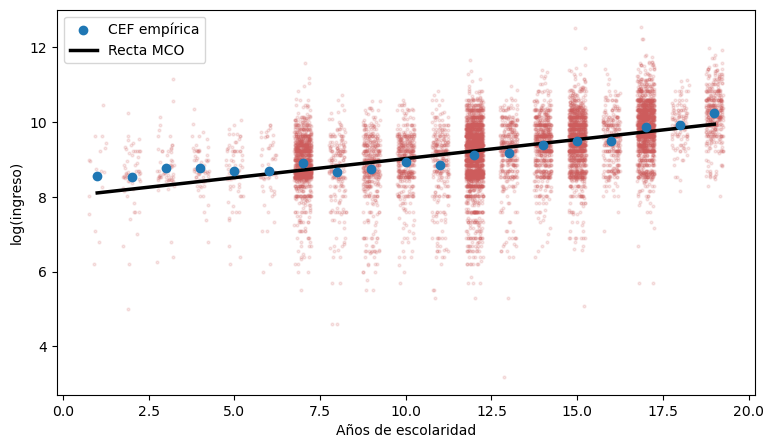

In [12]:
cef = df.groupby('aesc')['logingreso'].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.scatter(df['aesc'] + np.random.default_rng(0).uniform(-.25, .25, len(df)), df['logingreso'],
           s=4, alpha=.15, color='indianred')
ax.scatter(cef.index, cef.values, color='tab:blue', zorder=3, label='CEF empírica')
xs = np.linspace(df['aesc'].min(), df['aesc'].max(), 50)
ax.plot(xs, res.params['Intercept'] + res.params['aesc'] * xs, color='k', lw=2.5, label='Recta MCO')
ax.set_xlabel('Años de escolaridad'); ax.set_ylabel('log(ingreso)'); ax.legend()

## 4. Bondad de ajuste

### Propiedades algebraicas de los residuos
Con intercepto, MCO garantiza $\sum\hat\varepsilon_i=0$ y $\sum X_i\hat\varepsilon_i=0$ (vale en cualquier muestra).

In [13]:
print('Suma de residuos       :', res.resid.sum())
print('Suma de X * residuos   :', (df['aesc'] * res.resid).sum())

Suma de residuos       : -4.490630090003833e-12
Suma de X * residuos   : -8.151346264639869e-11


### Descomposición TSS = ESS + RSS y $R^2$

In [14]:
yhat = res.fittedvalues
TSS = ((y - y.mean())**2).sum()
ESS = ((yhat - y.mean())**2).sum()
RSS = (res.resid**2).sum()

print(f'TSS = {TSS:,.1f}')
print(f'ESS = {ESS:,.1f}')
print(f'RSS = {RSS:,.1f}')
print('ESS + RSS =', round(ESS + RSS, 1))
print()
print('R2 = ESS/TSS =', ESS / TSS)
print('R2 de statsmodels =', res.rsquared)

TSS = 7,412.7
ESS = 1,458.2
RSS = 5,954.5
ESS + RSS = 7412.7

R2 = ESS/TSS = 0.1967151587798602
R2 de statsmodels = 0.19671515877985957


### Error de predicción típico
$$\hat\sigma^2=\frac{RSS}{n-2},\qquad \hat\sigma=\sqrt{\hat\sigma^2}$$
(`statsmodels` lo llama `mse_resid`; es el "Root MSE" de Stata al sacar la raíz.)

In [15]:
n = int(res.nobs)
sigma2_hat = RSS / (n - 2)
print('sigma2 a mano      :', sigma2_hat)
print('mse_resid          :', res.mse_resid)
print('sigma_hat          :', np.sqrt(sigma2_hat))

sigma2 a mano      : 0.5927256263494101
mse_resid          : 0.5927256263494101
sigma_hat          : 0.7698867620302418


El $R^2$ es cercano a 0.2: la escolaridad por sí sola explica el 20% de la variación del log-ingreso. Un $R^2$ bajo no invalida el modelo: lo importante para el efecto marginal es que $\hat\beta_1$ esté bien estimado, lo que evaluamos en las próximas secciones.

## 5. Propiedades estadísticas: la distribución muestral de $\hat\beta_1$

En la práctica tenemos **una** muestra. Para entender las propiedades del estimador usamos una simulación: tratamos a toda la EAH como la *población* (con pendiente $\beta_1=0.102$) y extraemos muchas muestras aleatorias de cada tamaño $n$.

In [16]:
rng = np.random.default_rng(2026)
beta1_pob = res.params['aesc']
R = 1000  # muestras por tamaño

sims = {}
for n_s in (50, 200, 1000):
    est = np.empty(R)
    for r in range(R):
        muestra = df.sample(n=n_s, random_state=int(rng.integers(1e9)))
        est[r] = smf.ols('logingreso ~ aesc', data=muestra).fit().params['aesc']
    sims[n_s] = est

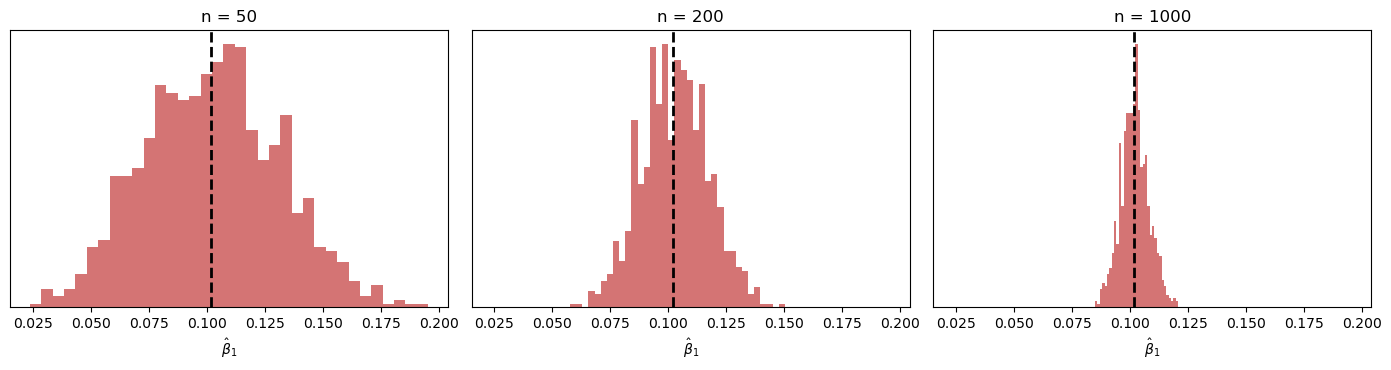

In [17]:
fig, axs = plt.subplots(1, 3, figsize=(14, 3.8), sharex=True)
for ax, (n_s, est) in zip(axs, sims.items()):
    ax.hist(est, bins=35, color='indianred', alpha=.85)
    ax.axvline(beta1_pob, color='k', ls='--', lw=2)
    ax.set_title(f'n = {n_s}'); ax.set_xlabel(r'$\hat\beta_1$'); ax.set_yticks([])
plt.tight_layout()

Dos resultados para comparar con la teoría:
- **Insesgadez**: la media de los $\hat\beta_1$ debería estar cerca de $\beta_1$.
- **Varianza**: $SD(\hat\beta_1)=\sigma/\sqrt{SST_x}$, que cae como $1/\sqrt n$.

In [18]:
SST_x = ((x - x.mean())**2).sum()
sigma_hat = np.sqrt(res.mse_resid)
N = len(df)

tabla = pd.DataFrame({
    'media de los beta1': {n_s: e.mean() for n_s, e in sims.items()},
    'desvío observado':   {n_s: e.std() for n_s, e in sims.items()},
    'teoría sigma/sqrt(SST_x)': {n_s: sigma_hat / np.sqrt(SST_x * n_s / N) for n_s in sims},
})
tabla.index.name = 'n'
print('beta1 poblacional =', round(beta1_pob, 4))
tabla.round(4)

beta1 poblacional = 0.102


,media de los beta1,desvío observado,teoría sigma/sqrt(SST_x)
n,,,
50,0.1023,0.0290,0.0291
200,0.1029,0.0143,0.0146
1000,0.1020,0.0060,0.0065


### Error estándar en la muestra completa
$$SE(\hat\beta_1)=\frac{\hat\sigma}{\sqrt{SST_x}}$$

In [19]:
print('SE a mano      :', sigma_hat / np.sqrt(SST_x))
print('SE statsmodels :', res.bse['aesc'])

SE a mano      : 0.0020559741350340364
SE statsmodels : 0.002055974135034041


## 6. Tests de hipótesis

Queremos testear $H_0:\beta_1=0$ contra $H_a:\beta_1\neq0$. Bajo normalidad de los errores (o muestra grande), $\hat T=\hat\beta_1/SE(\hat\beta_1)\sim t_{n-2}$.

In [20]:
t_stat = res.params['aesc'] / res.bse['aesc']
gl = res.df_resid
p_valor = 2 * stats.t.sf(abs(t_stat), gl)
valor_critico = stats.t.ppf(0.975, gl)

print('t            =', t_stat)
print('grados lib.  =', gl)
print('p-valor      =', p_valor)
print('valor crítico (5%) =', valor_critico)
print('statsmodels: t =', res.tvalues['aesc'], ' p =', res.pvalues['aesc'])

t            = 49.59989019527718
grados lib.  = 10046.0
p-valor      = 0.0
valor crítico (5%) = 1.960200153384677
statsmodels: t = 49.59989019527718  p = 0.0


### Intervalo de confianza al 95%

In [21]:
ic = res.params['aesc'] + np.array([-1, 1]) * valor_critico * res.bse['aesc']
print('IC a mano:', ic)
print(res.conf_int().loc['aesc'].values)

IC a mano: [0.09794597 0.10600621]
[0.09794597 0.10600621]


### Un test con una hipótesis nula distinta de cero

¿Rechazamos que el retorno de un año de escolaridad sea 5%? $H_0:\beta_1=0.05$

In [22]:
print(res.t_test('aesc = 0.05'))

                             Test for Constraints                             
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
c0             0.1020      0.002     25.281      0.000       0.098       0.106


### Significancia depende del tamaño de muestra
Una muestra chica puede no alcanzar para rechazar $H_0$ aunque el efecto sea real. Tomemos una muestra de $n=20$ de la misma población:

In [23]:
chica = df.sample(n=20, random_state=7)
res20 = smf.ols('logingreso ~ aesc', data=chica).fit()
print(res20.summary().tables[1])

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.1918      0.730     11.229      0.000       6.659       9.724
aesc           0.0764      0.058      1.312      0.206      -0.046       0.199


Un p-valor alto en una muestra chica **no** significa que $\beta_1=0$: significa que no tenemos precisión suficiente para distinguirlo de cero.

### ¿Son normales los residuos?
El resultado exacto $T\sim t_{n-2}$ exige errores normales, pero con $n$ grande el Teorema Central del Límite alcanza. Miremos los residuos:

Asimetría: -0.9382960235394994  Curtosis: 5.666444154589382


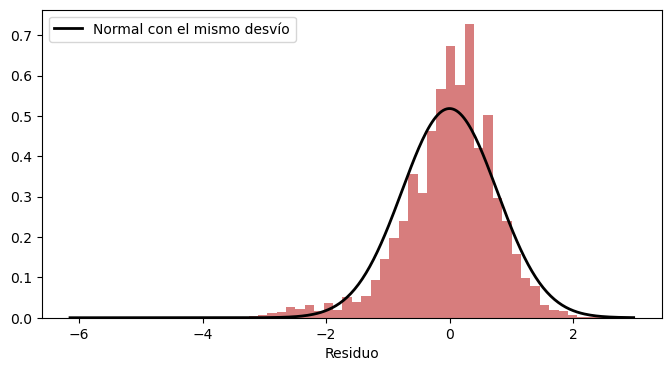

In [24]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(res.resid, bins=60, density=True, color='indianred', alpha=.8)
g = np.linspace(res.resid.min(), res.resid.max(), 300)
ax.plot(g, stats.norm.pdf(g, 0, np.sqrt(res.mse_resid)), 'k', lw=2, label='Normal con el mismo desvío')
ax.legend(); ax.set_xlabel('Residuo')
print('Asimetría:', stats.skew(res.resid), ' Curtosis:', stats.kurtosis(res.resid, fisher=False))

Los residuos son claramente asimétricos (no normales), pero con $n\approx10.000$ la distribución de $\hat T$ es aproximadamente normal por el TCL. Con $n=20$ esa aproximación es mucho menos confiable.

## 7. Práctica

1. Estimen el mismo modelo **separando por sexo** (`sexo`): ¿cambia $\hat\beta_1$? ¿Cambia el $R^2$?
2. Repitan la simulación de la Sección 5 con $n=100$ y verifiquen que el desvío observado coincide con $\sigma/\sqrt{SST_x}$.
3. Testeen $H_0:\beta_1=0.10$. ¿Se rechaza? ¿Cómo se relaciona con el intervalo de confianza?
4. Con una muestra de $n=50$, ¿cuál es el IC 95% de $\beta_1$? ¿Contiene el valor poblacional 0.102? Repitan 20 veces: ¿en cuántas ocasiones lo contiene?

In [25]:
# Espacio para trabajar